# 응용 03 · 필터와 Edge 픽셀 수 비교

`03_filters.py`의 A03 구현을 실행하고 원본·Gaussian·Median의 Edge 픽셀 수 차이를 표로 확인합니다.

흐름: 그레이스케일 잡음 이미지 읽기 → Gaussian·Median 적용 → 각 결과에 동일한 Canny 80/160 적용 → 이미지·CSV 저장 → 픽셀 수 비교.

필요 패키지: `opencv-python`, `numpy`, `pandas`, `matplotlib`, `IPython`. 프로젝트의 `.venv` 등 패키지가 설치된 커널에서 위에서부터 실행하세요. 실행 시 해당 실습의 `outputs/p03_` 결과가 다시 생성됩니다.

In [7]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

notebook_start = Path.cwd().resolve()
project = next((p for p in [notebook_start, *notebook_start.parents]
                if (p / "20261104/02_응용/03_filters.py").is_file()), None)
if project is None:
    raise FileNotFoundError("프로젝트 내부에서 실행하세요.")
exercise = project / "20261104/02_응용"


## 1. 필터 적용과 Canny 계산

| 항목 | 설정 | 처리 |
|---|---|---|
| 원본 | 필터 없음 | 동일 입력을 비교 기준으로 사용 |
| Gaussian | 커널 5×5, sigmaX=0 | 가우시안 가중 평균으로 주변 픽셀을 부드럽게 함 |
| Median | ksize=5 | 5×5 이웃의 중앙값으로 픽셀을 대체 |
| Canny | threshold1=80, threshold2=160 | 세 입력에 동일한 경계 추출 조건 적용 |

`np.count_nonzero(edge)`는 Canny 출력에서 0이 아닌 픽셀 수를 셉니다. 여기서는 경계 픽셀 값이 255입니다. 아래 코드는 현재 과제 파일과 동일하며, 노트북에서 사용할 수 있도록 `__file__` 기반 경로만 `exercise`로 바꿨습니다.

In [8]:
from pathlib import Path
import os
import cv2
import numpy as np

# 제공 코드: 어느 작업 폴더에서 실행해도 현재 파일 옆의 입력을 읽습니다.
# OpenCV에는 영문 상대 경로를 전달합니다. 원본 파일은 덮어쓰지 않습니다.
os.chdir(exercise)

import csv
import json
from time import perf_counter
Path("outputs").mkdir(exist_ok=True)

gray = cv2.imread("data/noisy_gray.png", cv2.IMREAD_GRAYSCALE)
# >>> TODO A03
# 같은 gray에 Gaussian (5,5), sigmaX=0과 Median ksize=5를 각각 적용하세요.
gaussian = cv2.GaussianBlur(gray, ksize=(5,5), sigmaX=0)
median = cv2.medianBlur(gray, ksize=5)
# <<< TODO A03
rows = []
for name, result in [("original", gray), ("gaussian", gaussian), ("median", median)]:
    edge = cv2.Canny(result, 80, 160)
    cv2.imwrite(f"outputs/p03_{name}.png", result)
    cv2.imwrite(f"outputs/p03_{name}_edge.png", edge)
    rows.append([name, int(np.count_nonzero(edge))])
with open("outputs/p03_edges.csv", "w", encoding="utf-8-sig", newline="") as f:
    w = csv.writer(f); w.writerow(["filter", "edge_pixels"]); w.writerows(rows)
print(rows)
print("Edge가 많다고 무조건 좋지 않습니다. 잡음 경계일 수도 있습니다.")


[['original', 11507], ['gaussian', 3234], ['median', 2582]]
Edge가 많다고 무조건 좋지 않습니다. 잡음 경계일 수도 있습니다.


## 2. Edge 픽셀 수와 원본 대비 차이

실행으로 생성한 `outputs/p03_edges.csv`를 읽습니다. 차이는 **현재 필터의 픽셀 수 − 원본 픽셀 수**로 계산하므로 음수는 원본보다 적다는 뜻입니다. 감소율은 **(원본 − 현재) / 원본 × 100**입니다.

In [9]:
counts = pd.read_csv("outputs/p03_edges.csv")
original_count = int(counts.loc[counts["filter"] == "original", "edge_pixels"].iloc[0])
comparison = counts.rename(columns={"filter": "필터", "edge_pixels": "Edge 픽셀 수"}).copy()
comparison["원본 대비 차이 (현재-원본)"] = comparison["Edge 픽셀 수"] - original_count
comparison["원본 대비 감소율 (%)"] = (
    (original_count - comparison["Edge 픽셀 수"]) / original_count * 100
).round(2) if original_count else float("nan")
display(comparison)
print("원본 Edge가 0이면 감소율은 정의할 수 없어 NaN으로 표시합니다.")

,필터,Edge 픽셀 수,원본 대비 차이 (현재-원본),원본 대비 감소율 (%)
0,original,11507,0,0.00
1,gaussian,3234,-8273,71.90
2,median,2582,-8925,77.56


원본 Edge가 0이면 감소율은 정의할 수 없어 NaN으로 표시합니다.


## 3. 필터 간 픽셀 수 차이

모든 조합을 같은 표에서 비교합니다. **차이 = 비교 대상 − 기준**입니다. 이 표는 개수 차이를 보여주며, 경계 픽셀의 위치가 얼마나 겹치는지를 나타내지는 않습니다.

In [10]:
by_filter = counts.set_index("filter")["edge_pixels"]
pair_rows = []
for base, target in [("original", "gaussian"), ("original", "median"), ("gaussian", "median")]:
    pair_rows.append({"기준": base, "비교 대상": target,
                      "기준 Edge 수": int(by_filter[base]),
                      "비교 대상 Edge 수": int(by_filter[target]),
                      "차이 (비교 대상-기준)": int(by_filter[target] - by_filter[base])})
pair_comparison = pd.DataFrame(pair_rows)
display(pair_comparison)

,기준,비교 대상,기준 Edge 수,비교 대상 Edge 수,차이 (비교 대상-기준)
0,original,gaussian,11507,3234,-8273
1,original,median,11507,2582,-8925
2,gaussian,median,3234,2582,-652


## 4. 필터 결과와 Edge 이미지

위 행은 필터 처리 이미지, 아래 행은 동일 조건으로 추출한 Edge입니다. 표에 기록된 픽셀 수와 함께 잡음 주변의 경계, 실제 물체 윤곽, 작은 세부 정보의 변화를 관찰합니다.

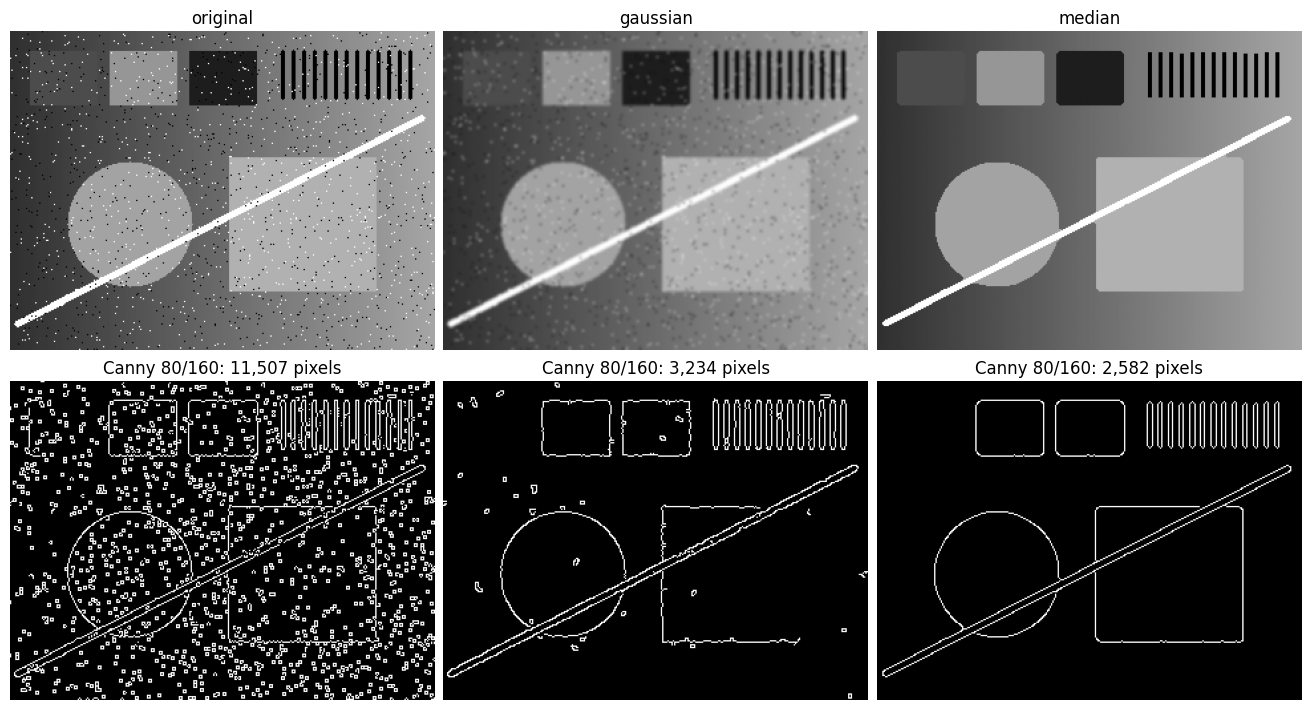

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for col, name in enumerate(["original", "gaussian", "median"]):
    filtered = cv2.imread(f"outputs/p03_{name}.png", cv2.IMREAD_GRAYSCALE)
    edge_image = cv2.imread(f"outputs/p03_{name}_edge.png", cv2.IMREAD_GRAYSCALE)
    axes[0, col].imshow(filtered, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(name)
    axes[1, col].imshow(edge_image, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"Canny 80/160: {int(by_filter[name]):,} pixels")
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.show()

## 5. 결과 검증

CSV와 저장된 Edge 이미지에서 센 값이 일치하는지 확인합니다. 실제 실행값을 확인하며 README의 예시 숫자를 정답으로 고정하지 않습니다.

In [12]:
assert counts["filter"].tolist() == ["original", "gaussian", "median"]
assert gaussian.shape == median.shape == gray.shape
for name, filtered in [("original", gray), ("gaussian", gaussian), ("median", median)]:
    edge_read = cv2.imread(f"outputs/p03_{name}_edge.png", cv2.IMREAD_GRAYSCALE)
    assert edge_read.shape == gray.shape
    assert set(np.unique(edge_read)).issubset({0, 255})
    assert np.array_equal(edge_read, cv2.Canny(filtered, 80, 160))
    assert int(np.count_nonzero(edge_read)) == int(by_filter[name])
print("검증 통과: 동일 크기·Canny 조건·저장 Edge·CSV 픽셀 수 일치")
os.chdir(notebook_start)

검증 통과: 동일 크기·Canny 조건·저장 Edge·CSV 픽셀 수 일치


## 결과를 읽을 때

- 필터를 적용하면 잡음 경계와 실제 경계가 함께 달라질 수 있습니다.
- Edge 수가 줄었다는 사실만으로 잡음만 제거됐다고 판단할 수 없습니다. 경계가 많다는 사실도 개선을 뜻하지 않습니다.
- 이 비교는 하나의 입력 이미지와 지정한 커널·임계값에 대한 결과입니다. 표와 이미지를 근거로 관찰하되 특정 필터가 가장 좋다는 결론은 작성하지 않습니다.